# Content

This notebook uses pandas for pre-handling the data to reduce its size, first by getting rid of sparse rows. 

Pandas is forbidden for this task, but it will save us time later by reducing the size of the data. The burden of working this way is obviously that our models miss data, hence are not as accurate as if we used all data rows. 

Also uses sklearn for PCA

# Imports

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import sklearn

# 1-Pre-handling data

#### a-Data opening

In [2]:
#Read input 
x_train_df = pd.read_csv('x_train.csv', sep=',')
print("Read x : OK")

#Read output
y_train_df = pd.read_csv('y_train.csv', sep=',')
print("Read y : OK")

Read x : OK
Read y : OK


#### b-Data cleaning

In [3]:
#Inputs
x_train_df_clean = x_train_df.dropna(axis = 1, how='any').dropna(how="any")

#Outputs
y_train_df_clean = y_train_df.dropna(how='all')

In [4]:
x_train_df

,Id,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,...,_PAREC1,_PASTAE1,_LMTACT1,_LMTWRK1,_LMTSCL1,_RFSEAT2,_RFSEAT3,_FLSHOT6,_PNEUMO2,_AIDTST3
0,0,53,11,11162015,11,16,2015,1100,2015015629,2015015629,...,1,1,3.0,3.0,4.0,1,1,NaN,NaN,2.0
1,1,33,12,12152015,12,15,2015,1200,2015004387,2015004387,...,9,9,3.0,3.0,4.0,9,9,NaN,NaN,NaN
2,2,20,10,10202015,10,20,2015,1100,2015005638,2015005638,...,4,2,2.0,2.0,3.0,1,1,1.0,2.0,2.0
3,3,42,6,6182015,6,18,2015,1100,2015004694,2015004694,...,2,2,2.0,2.0,3.0,1,1,2.0,2.0,2.0
4,4,24,11,11062015,11,6,2015,1100,2015004673,2015004673,...,9,9,3.0,3.0,4.0,1,1,9.0,9.0,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
328130,328130,49,7,11232015,11,23,2015,1100,2015006796,2015006796,...,2,2,3.0,3.0,4.0,1,1,NaN,NaN,2.0
328131,328131,51,5,6082015,6,8,2015,1100,2015006482,2015006482,...,1,1,3.0,3.0,4.0,1,1,NaN,NaN,1.0
328132,328132,39,10,10202015,10,20,2015,1100,2015004898,2015004898,...,3,2,3.0,3.0,4.0,1,2,2.0,2.0,2.0
328133,328133,33,12,12302015,12,30,2015,1100,2015004449,2015004449,...,3,2,3.0,3.0,4.0,1,1,NaN,NaN,2.0


In [5]:
x_train_df_clean

,Id,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,...,_PACAT1,_PAINDX1,_PA150R2,_PA300R2,_PA30021,_PASTRNG,_PAREC1,_PASTAE1,_RFSEAT2,_RFSEAT3
0,0,53,11,11162015,11,16,2015,1100,2015015629,2015015629,...,2,1,1,2,2,1,1,1,1,1
1,1,33,12,12152015,12,15,2015,1200,2015004387,2015004387,...,9,9,9,9,9,9,9,9,9,9
2,2,20,10,10202015,10,20,2015,1100,2015005638,2015005638,...,3,2,2,2,2,2,4,2,1,1
3,3,42,6,6182015,6,18,2015,1100,2015004694,2015004694,...,1,1,1,1,1,2,2,2,1,1
4,4,24,11,11062015,11,6,2015,1100,2015004673,2015004673,...,9,9,9,9,9,2,9,9,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
328130,328130,49,7,11232015,11,23,2015,1100,2015006796,2015006796,...,2,1,1,2,2,2,2,2,1,1
328131,328131,51,5,6082015,6,8,2015,1100,2015006482,2015006482,...,1,1,1,1,1,1,1,1,1,1
328132,328132,39,10,10202015,10,20,2015,1100,2015004898,2015004898,...,3,2,2,2,2,1,3,2,1,2
328133,328133,33,12,12302015,12,30,2015,1100,2015004449,2015004449,...,3,2,2,2,2,1,3,2,1,1


In [6]:
y_train_df

,Id,_MICHD
0,0,-1
1,1,-1
2,2,-1
3,3,-1
4,4,-1
...,...,...
328130,328130,-1
328131,328131,-1
328132,328132,-1
328133,328133,-1


In [7]:
print(f"Initial shape : {x_train_df.shape}")
print(f"Cleaned shape : {x_train_df_clean.shape}")

Initial shape : (328135, 322)
Cleaned shape : (328135, 83)


#### c-Save

In [8]:
#Input
x_train_df_clean.to_csv("x_train_clean.csv")

#Output
y_train_df_clean.to_csv("y_train_clean.csv")

# 2-First data analysis

#### a-Correlation

In [9]:
df_complete = x_train_df_clean.copy()
df_complete["_MICHD"] = y_train_df["_MICHD"]
df_complete

,Id,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,...,_PAINDX1,_PA150R2,_PA300R2,_PA30021,_PASTRNG,_PAREC1,_PASTAE1,_RFSEAT2,_RFSEAT3,_MICHD
0,0,53,11,11162015,11,16,2015,1100,2015015629,2015015629,...,1,1,2,2,1,1,1,1,1,-1
1,1,33,12,12152015,12,15,2015,1200,2015004387,2015004387,...,9,9,9,9,9,9,9,9,9,-1
2,2,20,10,10202015,10,20,2015,1100,2015005638,2015005638,...,2,2,2,2,2,4,2,1,1,-1
3,3,42,6,6182015,6,18,2015,1100,2015004694,2015004694,...,1,1,1,1,2,2,2,1,1,-1
4,4,24,11,11062015,11,6,2015,1100,2015004673,2015004673,...,9,9,9,9,2,9,9,1,1,-1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
328130,328130,49,7,11232015,11,23,2015,1100,2015006796,2015006796,...,1,1,2,2,2,2,2,1,1,-1
328131,328131,51,5,6082015,6,8,2015,1100,2015006482,2015006482,...,1,1,1,1,1,1,1,1,1,-1
328132,328132,39,10,10202015,10,20,2015,1100,2015004898,2015004898,...,2,2,2,2,1,3,2,1,2,-1
328133,328133,33,12,12302015,12,30,2015,1100,2015004449,2015004449,...,2,2,2,2,1,3,2,1,1,-1


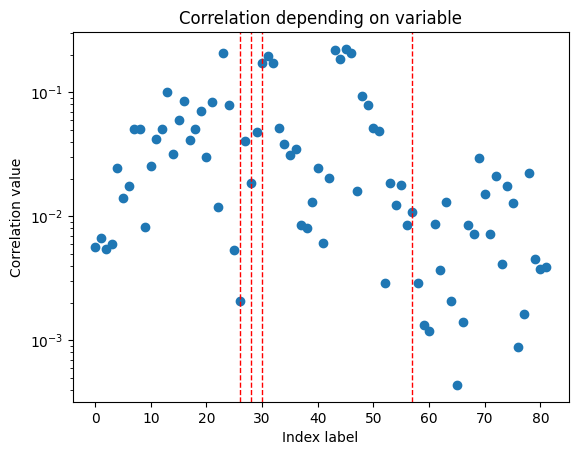

In [10]:
#Correlations
L_corr = []
for i in range(1, df_complete.shape[1]-1) :
    L_corr.append(df_complete._MICHD.corr(df_complete.iloc[:, i]))

#Display
plt.scatter([i for i in range(len(L_corr))], np.abs(np.array(L_corr)))
plt.xlabel("Index label")
plt.ylabel("Correlation value")
plt.yscale("log")
plt.title("Correlation depending on variable")

#Index identified in Notebook1
L_index_health = [26, 28, 30, 57]
for i in L_index_health :
    plt.axvline(x=i, color="red", linestyle="--", linewidth=1)
plt.show()

# 3-Covariance matrix

Text(0.5, 1.0, 'Heatmap covariance matrix data')

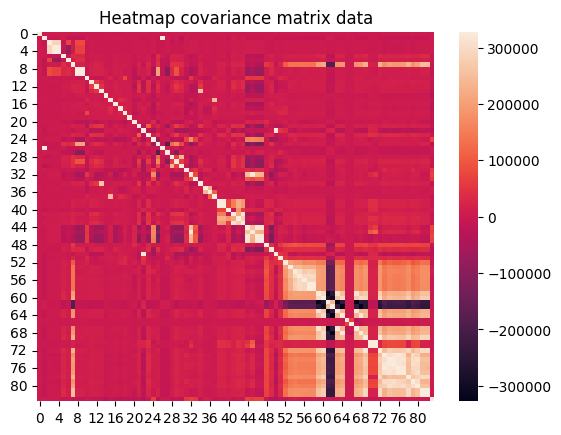

In [11]:
#Cleaned data matrix
M = df_complete.values
M_norm = (M - M.mean(axis=0))/M.std(axis=0)
Cov = M_norm.T @ M_norm

#Heatmap
sns.heatmap(Cov)
plt.title("Heatmap covariance matrix data")

# 4-PCA

#### a-Dimension reduction

In [12]:
pca_percentage = 0.999
pca = sklearn.decomposition.PCA(pca_percentage)
M_norm_PCA = pca.fit_transform(M_norm)

#PCA column number
L_pca_percentage = [0.9, 0.95, 0.99, 0.999]
for pca_percentage in L_pca_percentage :
    pca = sklearn.decomposition.PCA(pca_percentage)
    M_norm_PCA = pca.fit_transform(M_norm[:, :-1])
    print(f"PCA {pca_percentage * 100} % : {M_norm_PCA.shape[1]}")

PCA 90.0 % : 36
PCA 95.0 % : 42
PCA 99.0 % : 54
PCA 99.9 % : 65


In [13]:
pca_df = pd.DataFrame(M_norm_PCA)
pca_df_complete = pca_df.copy()
pca_df_complete["_MICHD"] = y_train_df["_MICHD"]
pca_df_complete

,0,1,2,3,4,5,6,7,8,9,...,56,57,58,59,60,61,62,63,64,_MICHD
0,-2.262086,-1.367023,-1.217651,-0.470084,3.482677,0.206818,-0.196914,-0.547160,2.459651,-0.690146,...,0.161384,-0.073494,-0.011848,-0.290812,0.109046,0.178541,0.051010,0.038839,0.017154,-1
1,13.373873,1.231652,-1.787166,-0.895874,1.651330,-0.551510,-3.438300,0.077354,0.157780,0.208052,...,0.023030,0.419769,-0.081312,-1.252421,0.086706,-0.117166,0.054482,-0.001099,0.092890,-1
2,-1.452337,2.235630,-0.318706,0.372495,1.689215,2.513572,-0.550449,-0.081578,-0.656538,0.379350,...,-0.056491,0.154362,-0.022762,0.118861,0.239351,-0.125672,0.005267,-0.090754,-0.042322,-1
3,-2.055836,1.607189,-0.020908,-0.023980,0.551378,-1.259041,1.409036,-0.377515,1.397073,0.276499,...,-0.051209,-0.049843,-0.018032,-0.202125,0.346536,0.158315,0.084247,0.021445,0.023639,-1
4,7.605756,2.645681,2.704846,4.307610,3.050658,10.578604,8.703240,9.034568,-0.935415,-0.484152,...,-0.065084,-0.236169,-0.080006,-0.262720,0.186811,-0.051712,0.063067,0.038801,-0.302155,-1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
328130,-2.053135,-0.445918,-1.059868,-0.013869,1.954566,1.006499,-0.197158,-0.932007,2.248765,-0.189886,...,0.319518,0.042571,-0.015341,0.271620,0.152770,-0.169132,-0.804936,-0.034836,-0.020216,-1
328131,-2.404822,-1.390992,-0.899722,0.228309,0.076987,-0.583821,0.815189,0.233507,2.069174,0.956543,...,-0.200101,0.074725,-0.049205,-0.249733,0.253237,-0.153382,-0.089256,0.075263,-0.049402,-1
328132,-1.563992,2.180711,0.021863,-0.311659,1.755842,-0.289296,-0.377962,0.920008,0.456441,-0.320317,...,-0.284141,0.075128,-0.027615,-0.169006,0.294625,-0.098900,0.034901,-0.196254,0.080839,-1
328133,-1.505030,-0.796994,-0.946941,-0.064369,1.416144,0.274252,-2.862677,1.849901,-0.735301,-1.324503,...,-0.180212,-0.071331,-0.373692,-0.188944,-0.160536,0.237501,-0.018909,-0.165802,0.163318,-1


#### b-PCA correlation

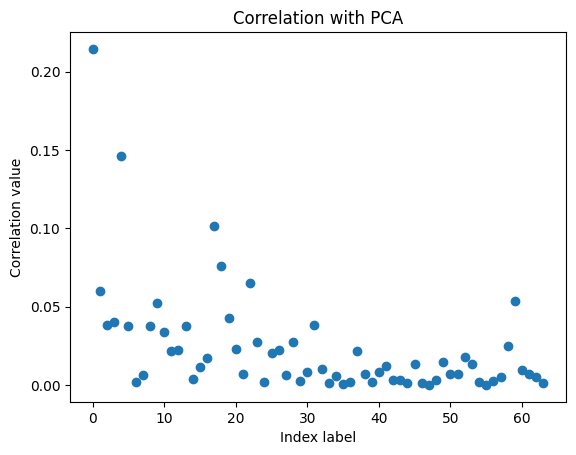

In [14]:
#Correlations
L_corr_PCA = []
for i in range(1, pca_df_complete.shape[1]-1) :
    L_corr_PCA.append(pca_df_complete._MICHD.corr(pca_df_complete.iloc[:, i]))

#Display
plt.scatter([i for i in range(len(L_corr_PCA))], np.abs(np.array(L_corr_PCA)))
plt.xlabel("Index label")
plt.ylabel("Correlation value")
plt.title("Correlation with PCA")
plt.show()

#### c-PCA vs all features correlations

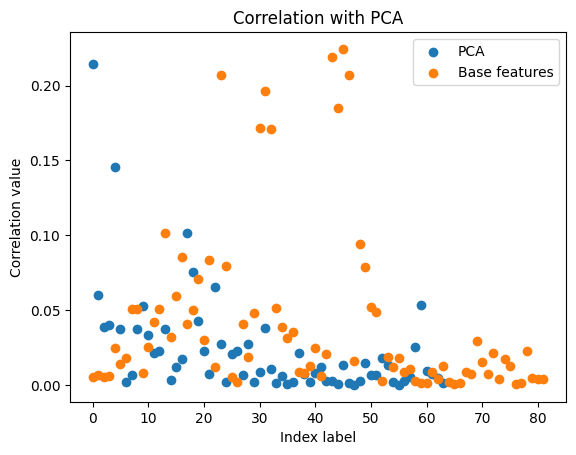

In [19]:
#Display
plt.scatter([i for i in range(len(L_corr_PCA))], np.abs(np.array(L_corr_PCA)), label="PCA")
plt.scatter([i for i in range(len(L_corr))], np.abs(np.array(L_corr)), label="Base features")
plt.xlabel("Index label")
plt.ylabel("Correlation value")
plt.title("Correlation with PCA")
plt.legend()
plt.show()

#### d-Singular values

In [16]:
x_train_df_clean.iloc[:, 10:]

,MENTHLTH,HLTHPLN1,PERSDOC2,BLOODCHO,CVDSTRK3,ASTHMA3,CHCOCNCR,CHCCOPD1,ADDEPEV2,CHCKIDNY,...,_PACAT1,_PAINDX1,_PA150R2,_PA300R2,_PA30021,_PASTRNG,_PAREC1,_PASTAE1,_RFSEAT2,_RFSEAT3
0,5,1,1,1,2,2,2,2,1,2,...,2,1,1,2,2,1,1,1,1,1
1,88,1,1,1,2,2,2,2,2,2,...,9,9,9,9,9,9,9,9,9,9
2,77,1,1,1,2,2,2,2,2,2,...,3,2,2,2,2,2,4,2,1,1
3,88,1,1,1,2,2,2,2,2,2,...,1,1,1,1,1,2,2,2,1,1
4,88,1,9,1,2,2,2,2,2,2,...,9,9,9,9,9,2,9,9,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
328130,88,1,1,1,2,2,1,2,2,2,...,2,1,1,2,2,2,2,2,1,1
328131,88,1,1,1,2,2,2,2,2,2,...,1,1,1,1,1,1,1,1,1,1
328132,1,1,1,1,2,2,2,2,1,2,...,3,2,2,2,2,1,3,2,1,2
328133,88,1,1,1,2,1,2,2,2,2,...,3,2,2,2,2,1,3,2,1,1


In [17]:
_, sigma, _ = np.linalg.svd(x_train_df_clean.iloc[:, 10:], full_matrices=False)
_, sigma_PCA, _ = np.linalg.svd(M_norm_PCA, full_matrices=False)

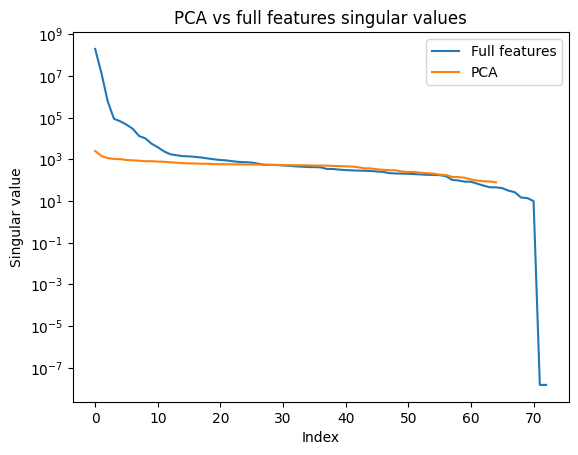

In [18]:
#Display
plt.plot(sigma, label="Full features")
plt.plot(sigma_PCA, label="PCA")
plt.xlabel("Index")
plt.ylabel("Singular value")
plt.title("PCA vs full features singular values")
plt.yscale("log")
plt.legend()
plt.show()